# 01 · Why Cropin's forest layer flags plantations as deforestation: QC error analysis

**Author:** Meera Mehta (data/EDA), MIT Analytics Lab × Cropin, Oct 2026
**Inputs:** `data/gee_exports/qc_error_analysis_A.csv`, `qc_error_analysis_B_ndvi.csv` (from `gee/02_qc_error_analysis_export.js`)
**Outputs:** `data/processed/qc_features.csv`, `figures/01*.png`

This notebook rebuilds my preliminary EDA from the raw Earth Engine exports, with every step
justified. It replaces the quick scripts in `_handoff/reference/old_analysis/`. Everything here is
**exploratory**: the features were chosen after looking at these same 433 cases. Treat the
results as hypotheses to test on new data, not as validated performance.

**How to read the statistics.** Each term is explained where it first appears. In short:
- **AUC**: the chance that a randomly chosen plantation scores "more plantation-like" than a randomly chosen forest. 0.5 is a coin flip; 1.0 is perfect separation.
- **p-value**: how surprising the observed difference would be if there were truly no difference. Small means "unlikely to be chance alone". It does not measure how *big* or *useful* the difference is.
- **95% confidence interval (CI)**: the range of values plausible given our small sample.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from qc_analysis import *   # shared helpers: loading, features, stats, CV (see src/qc_analysis.py)

warnings.filterwarnings("ignore", category=FutureWarning)
# NumPy 2.x + Apple Accelerate emits spurious "divide by zero/overflow in matmul" warnings inside
# sklearn's logistic regression on macOS. Predictions are checked to be finite in cv_evaluate().
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)
set_style()
SEED = 0
np.random.seed(SEED)
N_BOOT = 2000
pd.set_option("display.precision", 3, "display.width", 140)

## a. The question and the data

**Question.** Cropin's forest layer flags clearings in places it believes were forest. Many
of these turn out to be **plantation harvests** (eucalyptus or pine being cut on schedule). Under
the EU Deforestation Regulation these are false alarms, and they can cut a farmer off from buyers.
*What distinguishes those plantations from real native forest, using public data at 10–30 m?*

**The QC cases.** Cropin staff hand-checked 433 alerts against historical Google Earth imagery:
- **310 `plantation`**: a harvest, i.e. a false alarm;
- **123 `forest`**: real deforestation.

**Why this sample is biased, and what that means.**
1. **Pre-filtered.** Every case was already called "forest" by Cropin's layer *and* already
   cleared in 2026. We never see plantations the layer handled correctly, or forest it missed.
   So nothing here estimates the layer's overall accuracy.
2. **Skewed classes.** 72% are plantations, far more than in the landscape. Any precision we
   compute is inflated relative to real-world use.
3. **Tiny and clustered.** Median ≈ 270 m², about 3 Sentinel-2 pixels and smaller than one
   30 m MapBiomas pixel. Many polygons sit within a few km of each other (handled in section e).

We also split plantations by what **MapBiomas Collection 9 (30 m)** said in **2020** (the EUDR
cutoff year). This splits plantations into "missed" (MapBiomas said forest), "caught" (MapBiomas
said plantation) and "other".

,n
qc_label,
Plantation (false alarm),310
Forest (real deforestation),123


,n
group,
"plantation, MapBiomas 2020 said forest (missed)",282
"plantation, MapBiomas 2020 said plantation (caught)",11
"plantation, MapBiomas 2020 said something else",17
forest (real deforestation),123


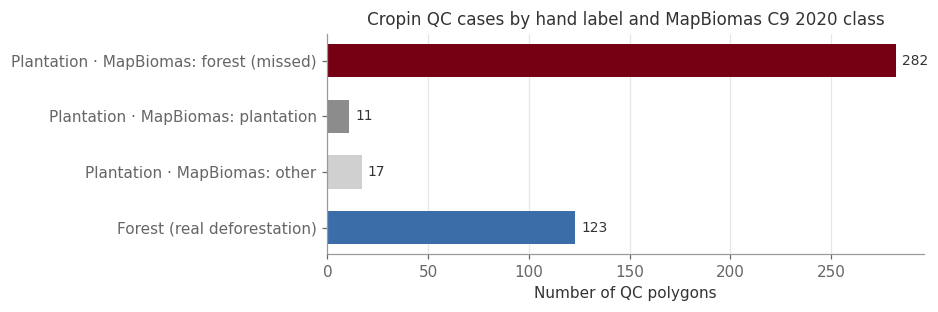

In [2]:
d = add_features(load_qc())
counts = pd.DataFrame({
    "n": d["qc_label"].value_counts(),
}).rename(index=LABELS)
display(counts)
grp = d["group"].value_counts().reindex(["plant_missed", "plant_caught", "plant_other", "forest"])
display(grp.rename({"plant_missed": "plantation, MapBiomas 2020 said forest (missed)",
                    "plant_caught": "plantation, MapBiomas 2020 said plantation (caught)",
                    "plant_other":  "plantation, MapBiomas 2020 said something else",
                    "forest": "forest (real deforestation)"}).to_frame("n"))

fig, ax = plt.subplots(figsize=(7, 2.6))
order = ["forest", "plant_other", "plant_caught", "plant_missed"]
names = ["Forest (real deforestation)", "Plantation · MapBiomas: other",
         "Plantation · MapBiomas: plantation", "Plantation · MapBiomas: forest (missed)"]
cols = [PAL["forest"], PAL["light"], PAL["grey"], PAL["plantation"]]
ax.barh(names, grp.reindex(order).values, color=cols, height=0.6)
for i, v in enumerate(grp.reindex(order).values):
    ax.text(v + 3, i, str(v), va="center", fontsize=9)
ax.set_xlabel("Number of QC polygons")
ax.set_title("Cropin QC cases by hand label and MapBiomas C9 2020 class")
ax.grid(axis="y", visible=False)
savefig(fig, "01a_qc_groups"); plt.show()

## b. Loading, merging and checks

The two exports come from the same 433 polygons (`gee/02_qc_error_analysis_export.js`):
- **A** holds the map-based features;
- **B** holds the yearly Sentinel-2 NDVI.

`load_qc()` merges them on `id` with a strict one-to-one join. It asserts that ids are unique,
identical in both files, and carry the same `qc_label`. Below we also check for missing values,
for the MapBiomas "no data" class (0), and for how many clear satellite views each year has.

In [3]:
print("rows:", len(d), "| unique ids:", d["id"].nunique())
na = d.isna().sum(); print("columns with missing values:", int((na > 0).sum()))
key = duplicate_key(d)
rep = d.groupby(key).agg(n=("id", "size"), ids=("id", list), label=("qc_label", "first"))
rep = rep[rep.n > 1]
print(f"repeated polygons: {len(rep)} locations appear more than once -> {int((rep.n - 1).sum())} redundant rows "
      f"({int(((rep.n - 1) * (rep.label == 'plantation')).sum())} plantation, {int(((rep.n - 1) * (rep.label == 'forest')).sum())} forest); "
      f"labels agree within every group: {d.groupby(key).qc_label.nunique().max() == 1}")
print("repeated id groups:", rep.ids.tolist())
print("unique polygons:", len(dedupe(d)))
zero = (d[MB_COLS] == 0)
print(f"MapBiomas 'no data' (class 0): {int(zero.sum().sum())} polygon-years in {int(zero.any(axis=1).sum())} polygons")

nobs = d[[f"n_obs_{y}" for y in range(2017, 2026)]].median().rename(lambda c: c[-4:])
display(nobs.to_frame("median clear Sentinel-2 views per pixel").T.round(1))

rows: 433 | unique ids: 433
columns with missing values: 0
repeated polygons: 12 locations appear more than once -> 13 redundant rows (8 plantation, 5 forest); labels agree within every group: True
repeated id groups: [[272, 279], [2, 18], [218, 227], [25, 26, 27], [194, 255], [216, 228], [344, 347], [69, 70], [47, 48], [391, 392], [189, 211], [206, 246]]
unique polygons: 420
MapBiomas 'no data' (class 0): 12 polygon-years in 9 polygons


,2017,2018,2019,2020,2021,2022,2023,2024,2025
median clear Sentinel-2 views per pixel,5.0,10.0,30.0,36.6,32.0,28.0,29.0,25.5,35.3


**Reading the checks.**
- No missing values.
- ⚠️ **Repeated polygons.** 12 locations appear 2–3 times in Cropin's file (13 redundant rows:
  8 plantation, 5 forest). The copies overlap 100% (IoU = 1.0) and differ only by floating-point
  noise in the coordinates, so every feature is identical. The labels always agree. They might be
  repeat alerts on the same spot, or a copy error; **we need to ask Cropin**. We keep all 433 rows
  as the main analysis, to match Cropin's file and the preliminary numbers. Copies always fall in
  the same spatial block, so the spatially blocked CV in section e is unaffected. Section f repeats
  the key results on the 420 unique polygons.
- A handful of polygon-years have MapBiomas class 0 (no data). We keep them as they are. They
  add a few spurious "class changes" in 9 polygons, which is too few to matter, and we flag it here.
- Clear Sentinel-2 views are scarce in **2017 (median 5)** and **2018 (median 10)**, against
  25–37 from 2019 on. With 5 views a yearly 10th percentile is basically one image, so **NDVI
  features use 2019–2024 by default**. 2025 is excluded because it may already contain the
  clearing that triggered the alert. The original 2017–2024 versions are kept with the suffix
  `_17_24`, for the reproducibility check in section f.

### Derived features: exact definitions
All land-history features use `mb_1985`…`mb_2023`, the **MapBiomas C9 class of the 30 m pixel(s)
under the polygon** (Earth Engine `mode`). They therefore describe MapBiomas' *opinion* of the
history, not ground truth.

| Feature | Definition |
|---|---|
| `n_yrs_forest` | number of years (of 39) with class 3 |
| `n_class_changes` | number of consecutive-year pairs whose class differs (0–38) |
| `forest_every_year` | 1 if class 3 in all 39 years |
| `since` | first year of the final unbroken run of class 3 ending in 2023. 1985 if always forest; 2024 if not forest in 2023 |
| `after2000` | 1 if `since` > 2000, i.e. forest only recently, or not forest at the end |
| `farm_any` | 1 if any year is class 21 (mosaic), 41 (other temporary crop), 19 (other crop), 12 (grassland) or 15 (pasture) |
| `min_p10` | lowest yearly NDVI 10th percentile, 2019–2024 (a harvest would show as a dip) |
| `n_dip_years`, `any_dip` | years with NDVI p10 < 0.5, and whether there is at least one |
| `mean_med`, `sd_med` | mean and std dev of the yearly NDVI medians, 2019–2024 |

In [4]:
FEATS = ["n_yrs_forest", "n_class_changes", "forest_every_year", "since", "after2000", "farm_any",
         "min_p10", "n_dip_years", "any_dip", "mean_med", "sd_med"]
display(d.groupby("qc_label")[FEATS].median().T.rename(columns=LABELS))
out = DATA / "processed/qc_features.csv"
d.to_csv(out, index=False)
print(f"saved {out.relative_to(ROOT)}  ({d.shape[0]} rows x {d.shape[1]} columns, local only, not committed)")

qc_label,Forest (real deforestation),Plantation (false alarm)
n_yrs_forest,39.000,35.000
n_class_changes,0.000,1.000
forest_every_year,1.000,0.000
since,1985.000,1994.000
after2000,0.000,0.000
farm_any,0.000,0.000
min_p10,0.611,0.604
n_dip_years,0.000,0.000
any_dip,0.000,0.000
mean_med,0.853,0.861


saved data/processed/qc_features.csv  (433 rows x 96 columns, local only, not committed)


## c. Benchmark: what did MapBiomas say about these cases?

MapBiomas is the best open land-cover map of Brazil and has a dedicated **forest plantation**
class (9). If it already recognised these plantations, the problem would be solved. We look at
its class in **2020**, the EUDR cutoff year.

In [5]:
tab = pd.crosstab(d["qc_label"], d["mb2020_group"]).reindex(columns=["called forest", "called plantation", "called other"], fill_value=0)
tab_pct = (100 * tab.div(tab.sum(axis=1), axis=0)).round(1)
display(tab.rename(index=LABELS)); display(tab_pct.rename(index=LABELS).astype(str) + " %")
other = d.loc[d["mb2020_group"] == "called other"].groupby("qc_label")["mb_2020"].value_counts()
print("'other' classes in 2020:", other.to_dict())

mb2020_group,called forest,called plantation,called other
qc_label,,,
Forest (real deforestation),120,0,3
Plantation (false alarm),282,11,17


mb2020_group,called forest,called plantation,called other
qc_label,,,
Forest (real deforestation),97.6 %,0.0 %,2.4 %
Plantation (false alarm),91.0 %,3.5 %,5.5 %


'other' classes in 2020: {('forest', 21.0): 3, ('plantation', 21.0): 17}


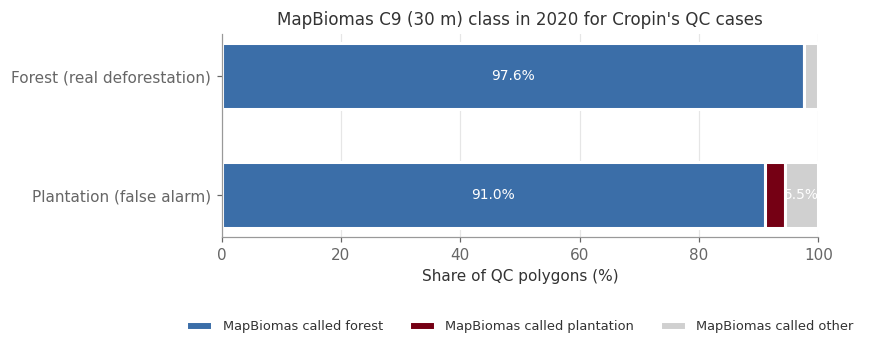

In [6]:
fig, ax = plt.subplots(figsize=(7, 2.4))
left = np.zeros(2)
for cls, colr in [("called forest", PAL["forest"]), ("called plantation", PAL["plantation"]), ("called other", PAL["light"])]:
    v = tab_pct.loc[["plantation", "forest"], cls].values
    ax.barh([LABELS["plantation"], LABELS["forest"]], v, left=left, color=colr, height=0.55,
            edgecolor="white", linewidth=2, label=f"MapBiomas {cls}")
    for i, (l, w) in enumerate(zip(left, v)):
        if w > 4: ax.text(l + w / 2, i, f"{w:.1f}%", ha="center", va="center", color="white", fontsize=9)
    left += v
ax.set_xlim(0, 100); ax.set_xlabel("Share of QC polygons (%)")
ax.set_title("MapBiomas C9 (30 m) class in 2020 for Cropin's QC cases")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.35), fontsize=8.5)
ax.grid(axis="y", visible=False)
savefig(fig, "01c_mapbiomas_2020"); plt.show()

**Result.** MapBiomas C9 called **282 of 310 plantations (91.0%) natural forest** in 2020. It
caught only **11 (3.5%)** as plantation; 17 were "mosaic of uses". For real forests it said
forest 120 times and mosaic 3 times. So the 30 m map gives almost no help with these false alarms.

### The same, year by year (2016–2023)
MapBiomas reprocesses its whole history with each collection, and the label of a pixel can
change from year to year. If plantations were growing up or being better recognised, the share
caught should rise in later years.

,2016,2017,2018,2019,2020,2021,2022,2023
plantations called forest (%),89.7,91.0,90.6,91.0,91.0,88.4,88.7,88.4
plantations called plantation (n),10.0,9.0,9.0,11.0,11.0,20.0,20.0,20.0
plantations called plantation (%),3.2,2.9,2.9,3.5,3.5,6.5,6.5,6.5
forests called forest (%),95.9,96.7,96.7,96.7,97.6,96.7,96.7,96.7
forests called plantation (n),0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0


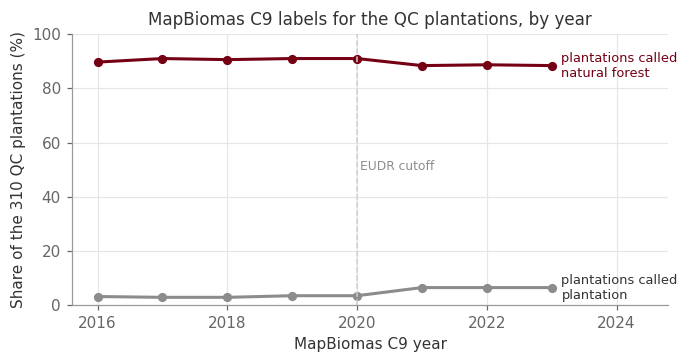

In [7]:
yrs = range(2016, 2024)
by_year = pd.DataFrame({
    y: {
        "plantations called forest (%)":     100 * (d.loc[d.y == 1, f"mb_{y}"] == 3).mean(),
        "plantations called plantation (n)": int((d.loc[d.y == 1, f"mb_{y}"] == 9).sum()),
        "plantations called plantation (%)": 100 * (d.loc[d.y == 1, f"mb_{y}"] == 9).mean(),
        "forests called forest (%)":         100 * (d.loc[d.y == 0, f"mb_{y}"] == 3).mean(),
        "forests called plantation (n)":     int((d.loc[d.y == 0, f"mb_{y}"] == 9).sum()),
    } for y in yrs}).round(1)
display(by_year)

fig, ax = plt.subplots(figsize=(7, 3.2))
x = list(yrs)
ax.plot(x, by_year.loc["plantations called forest (%)"], color=PAL["plantation"], marker="o", ms=5)
ax.plot(x, by_year.loc["plantations called plantation (%)"], color=PAL["grey"], marker="o", ms=5)
ax.text(2023.15, by_year.loc["plantations called forest (%)", 2023], "plantations called\nnatural forest", va="center", fontsize=8.5, color=PAL["plantation"])
ax.text(2023.15, by_year.loc["plantations called plantation (%)", 2023], "plantations called\nplantation", va="center", fontsize=8.5, color=PAL["ink"])
ax.axvline(2020, color=PAL["light"], lw=1, ls="--"); ax.text(2020.05, 50, "EUDR cutoff", fontsize=8, color=PAL["grey"])
ax.set_ylim(0, 100); ax.set_xlim(2015.6, 2024.8)
ax.set_xlabel("MapBiomas C9 year"); ax.set_ylabel("Share of the 310 QC plantations (%)")
ax.set_title("MapBiomas C9 labels for the QC plantations, by year")
savefig(fig, "01c_mapbiomas_by_year"); plt.show()

**Reading it.** The share of plantations MapBiomas calls plantation rises a little after 2020,
but stays small. This year-to-year relabelling is why the "miss rate" depends on which MapBiomas
year you quote.

**Reconciling with Julia's 82%.** Julia reported 249 of 303 plantations missed (82%). Her figure
and our 91% are both valid, but they are measured differently:
- **Product and year.** Her committed script (`data_exploration/MapBiomass_comparisons_QCData.js`)
  uses the **MapBiomas 10 m Collection 4, year 2025**, MapBiomas' latest view before the 2026
  clearings. Ours is the **30 m Collection 9, year 2020**, the EUDR cutoff.
- **Cases dropped.** She dropped 14 cases (n = 419). We don't know why yet. A likely reason is
  polygons with no 10 m pixel classified as forest or plantation.

The 10 m product sees more stand edges, and the later year gives MapBiomas more time to
recognise the stands, so 82% < 91% is expected. We can't reproduce her number here because our
exports don't include Collection 4. Notebook 02 benchmarks the 10 m C2 and S2-beta products that
Cropin's own layer uses. **To do:** confirm her release and the 14 dropped ids, and share one feature table.

## d. Six findings, one at a time

**How every finding is tested.**
- **Continuous features** (e.g. height): the **Mann–Whitney U test**. It asks whether values in
  one group tend to be larger than in the other. It uses only ranks, so it doesn't assume a bell
  curve and isn't thrown off by outliers. Our features are skewed and bounded, so that matters.
  Its effect size is exactly the **AUC**, which we report with a **bootstrap 95% CI**: resample
  the 433 polygons with replacement 2,000 times, recompute the AUC each time, and take the middle 95%.
- **Yes/no features** (e.g. "ever farmland"): **Fisher's exact test** on the 2×2 table. It is
  exact, so it stays valid with small counts. The effect size is the **odds ratio (OR)**: OR = 2
  means the odds of having the trait are twice as high in the first group; OR = 1 means no difference.
- **Many tests at once.** Running many tests raises the chance that at least one looks significant
  by luck. We apply the **Holm correction** across all the tests in this section (collected at the
  end of d) and report raw and adjusted p-values. Holm controls the chance of *any* false positive
  and is uniformly better than plain Bonferroni.

AUCs are oriented so that **> 0.5 means the feature separates the classes**; the direction is stated.

In [8]:
pl, fo = d[d.y == 1], d[d.y == 0]
mi = d[d.group == "plant_missed"]
TESTS = []   # collected for the Holm correction

def report_continuous(col, finding, a=pl, b=fo, label_a="plantation", label_b="forest"):
    yy = np.r_[np.ones(len(a)), np.zeros(len(b))]; xx = np.r_[a[col].values, b[col].values]
    auc, lo, hi = auc_ci(yy, xx, N_BOOT, SEED)
    p = mwu_test(a[col], b[col])
    TESTS.append(dict(finding=finding, feature=col, test="Mann-Whitney U", comparison=f"{label_a} vs {label_b}",
                      effect=f"AUC {auc:.2f} ({lo:.2f}-{hi:.2f})", p_raw=p))
    print(f"{col}: median {label_a} {a[col].median():.3g} vs {label_b} {b[col].median():.3g} | "
          f"AUC {auc:.3f} (95% CI {lo:.3f}-{hi:.3f}), {auc_oriented(yy, xx)[1]} | Mann-Whitney p = {p:.1e}")
    return auc, lo, hi, p

def report_binary(col, finding, a, b, label_a, label_b):
    r = fisher_test(a[col], b[col])
    TESTS.append(dict(finding=finding, feature=col, test="Fisher exact", comparison=f"{label_a} vs {label_b}",
                      effect=f"OR {r['odds_ratio']:.2f}", p_raw=r["p"]))
    print(f"{col}: {label_a} {r['pct_a']:.1f}% ({r['n_a']}/{r['N_a']}) vs {label_b} {r['pct_b']:.1f}% ({r['n_b']}/{r['N_b']}) | "
          f"OR {r['odds_ratio']:.2f} | Fisher p = {r['p']:.1e}")
    return r

### Finding 1: Google's Natural Forests probability separates the groups, but at a cost to forest

**Hypothesis.** Google's *Natural Forests of the World 2020* map gives each 10 m pixel a
probability of being **natural** (not planted) forest. Its model was trained to tell plantations
from native forest using texture and spectral and temporal cues. So plantations should score low.

**Measurement.** Mean probability inside each polygon (`nf_prob`, raw band ÷ 250).
**Limitations:**
- It is a 2020 snapshot.
- It is itself a model with its own errors in southern Brazil.
- It may have learned from MapBiomas-like labels, so its errors could be correlated with MapBiomas'.

nf_prob: median plantation 0.443 vs forest 0.76 | AUC 0.718 (95% CI 0.662-0.769), lower in plantations | Mann-Whitney p = 1.3e-12


,cutoff,plantations_caught,pct_plantations_caught,forests_hidden,pct_forests_hidden
0,0.10,49,15.8,6,4.9
1,0.15,71,22.9,7,5.7
2,0.20,91,29.4,12,9.8
3,0.30,115,37.1,19,15.4
4,0.50,172,55.5,32,26.0


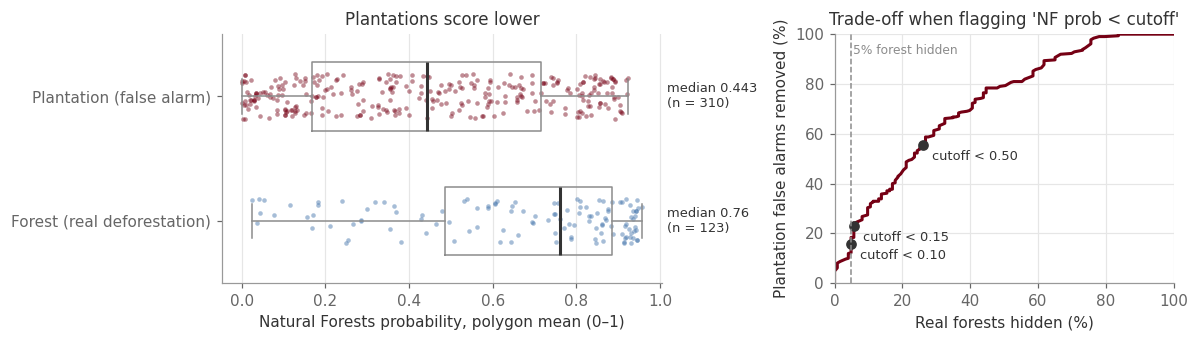

In [9]:
f1 = report_continuous("nf_prob", "1 Natural Forests")
thr = pd.DataFrame([dict(cutoff=t, plantations_caught=int((pl.nf_prob < t).sum()),
                         pct_plantations_caught=100 * (pl.nf_prob < t).mean(),
                         forests_hidden=int((fo.nf_prob < t).sum()),
                         pct_forests_hidden=100 * (fo.nf_prob < t).mean()) for t in [0.10, 0.15, 0.20, 0.30, 0.50]])
display(thr.round({"pct_plantations_caught": 1, "pct_forests_hidden": 1}))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw=dict(width_ratios=[1.3, 1]))
dist_plot(axs[0], d, "nf_prob", "Natural Forests probability, polygon mean (0–1)")
axs[0].set_title("Plantations score lower")
ts = np.linspace(0, 1, 201)
axs[1].plot([100 * (fo.nf_prob < t).mean() for t in ts], [100 * (pl.nf_prob < t).mean() for t in ts], color=PAL["plantation"])
for t in [0.10, 0.15, 0.5]:
    xh, yc = 100 * (fo.nf_prob < t).mean(), 100 * (pl.nf_prob < t).mean()
    axs[1].plot(xh, yc, "o", color=PAL["ink"], ms=6); axs[1].annotate(f"cutoff < {t:.2f}", (xh, yc), xytext=(6, -10), textcoords="offset points", fontsize=8.5)
axs[1].axvline(5, color=PAL["grey"], ls="--", lw=1); axs[1].text(5.5, 92, "5% forest hidden", fontsize=8, color=PAL["grey"])
axs[1].set_xlabel("Real forests hidden (%)"); axs[1].set_ylabel("Plantation false alarms removed (%)")
axs[1].set_xlim(0, 100); axs[1].set_ylim(0, 100); axs[1].set_title("Trade-off when flagging 'NF prob < cutoff'")
plt.tight_layout(); savefig(fig, "01d1_natural_forests"); plt.show()

**Result.**
- **Separation.** Plantations have a median NF probability of 0.44 against 0.76 for forests:
  AUC 0.72 (95% CI 0.66–0.77), p ≈ 1e-12.
- **Usefulness.** It costs forest quickly. Calling everything below 0.10 a plantation removes 16%
  of false alarms but hides 5% of real deforestation (6 of 123). At the map's natural 0.5 cutoff
  it hides 26% of real forest.
- **Verdict.** A useful ingredient, but not a standalone filter.

### Finding 2: plantations are taller

**Hypothesis.** Commercial eucalyptus and pine grow fast and are bred for height. Secondary
native forest in the south is often younger or degraded. So the QC plantations should be taller.

**Measurement.** Mean of the ETH Global Canopy Height 2020 (10 m) inside the polygon.
**Limitations:**
- **Timing.** ETH is a 2020 snapshot and the clearings happened in 2026. A stand harvested and
  replanted in between would be short in 2020, so recent rotations blur the signal.
- **Model error.** ETH is itself a model, trained on GEDI lidar, with roughly ±several metres of error.

height_mean: median plantation 24.2 vs forest 21.2 | AUC 0.706 (95% CI 0.650-0.759), higher in plantations | Mann-Whitney p = 2.3e-11


,height_over_m,pct_plantations,pct_forests
0,20,86.1,61.8
1,25,44.2,18.7
2,30,9.4,3.3


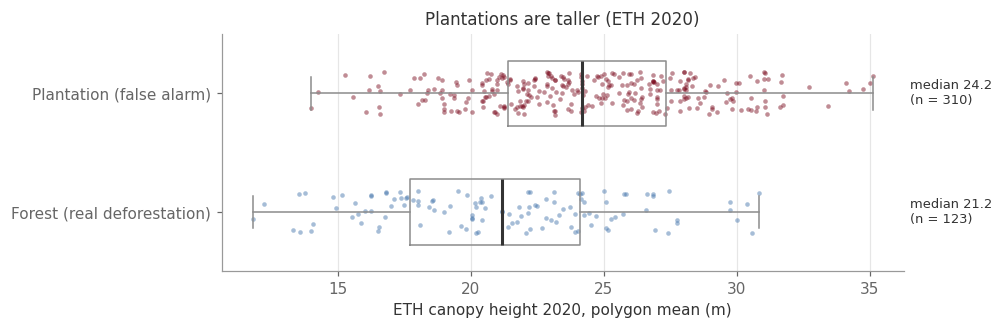

In [10]:
f2 = report_continuous("height_mean", "2 Height")
display(pd.DataFrame([dict(height_over_m=t, pct_plantations=100 * (pl.height_mean > t).mean(),
                           pct_forests=100 * (fo.height_mean > t).mean()) for t in [20, 25, 30]]).round(1))
fig, ax = plt.subplots(figsize=(8, 2.8))
dist_plot(ax, d, "height_mean", "ETH canopy height 2020, polygon mean (m)")
ax.set_title("Plantations are taller (ETH 2020)")
savefig(fig, "01d2_height"); plt.show()

**Result.** Median height is 24.2 m for plantations against 21.2 m for forests: AUC 0.71 (CI
0.65–0.76), p ≈ 2e-11. 44% of plantations are over 25 m, against 19% of forests.

### Finding 3: plantations look *more* uneven in height, against the hypothesis

**Hypothesis (original).** Plantations are planted at the same time with one species, so their
canopy should be **more uniform** than native forest. That would mean a *lower* height SD.

**Measurement.** Std dev of ETH height in a **30 m-radius circle around the polygon centroid**,
at 10 m (`height_sd_30m`). The circle was used because a ~270 m² polygon has too few 10 m pixels
to compute a spread.
**Limitation (important):** the circle covers about 2,800 m², roughly ten times the polygon. It
therefore measures the **patchwork around the stand**, which in plantation landscapes includes
roads, firebreaks, neighbouring blocks of other ages and fields. It does not measure texture inside the stand.

height_sd_30m: median plantation 1.48 vs forest 1.12 | AUC 0.663 (95% CI 0.607-0.719), higher in plantations | Mann-Whitney p = 1.2e-07
SD > 1.5 m: plantations 49.4% vs forests 27.6%


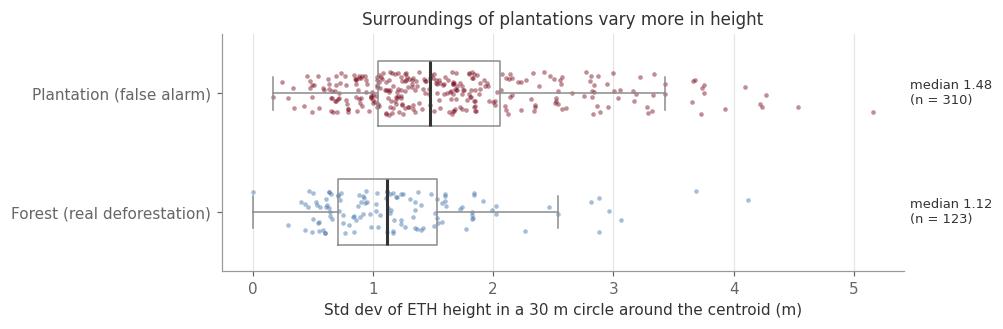

In [11]:
f3 = report_continuous("height_sd_30m", "3 Height SD (30 m circle)")
print(f"SD > 1.5 m: plantations {100*(pl.height_sd_30m>1.5).mean():.1f}% vs forests {100*(fo.height_sd_30m>1.5).mean():.1f}%")
fig, ax = plt.subplots(figsize=(8, 2.8))
dist_plot(ax, d, "height_sd_30m", "Std dev of ETH height in a 30 m circle around the centroid (m)")
ax.set_title("Surroundings of plantations vary more in height")
savefig(fig, "01d3_height_sd"); plt.show()

**Result.** The direction is the *opposite* of the hypothesis. The median SD is 1.48 m around
plantations against 1.12 m around forests: AUC 0.66 (CI 0.61–0.72), p ≈ 1e-7. Julia sees the
same on the MapBiomas reference points.

**Most likely explanation.** This is the measurement artefact described above: the circle
captures the edges of the plantation block, not the stand's interior. Uddesh's high-resolution
imagery shows plantations smooth *inside*. Notebook 02 tests this directly with the **Meta 1 m
canopy height measured inside each polygon**. It is still a usable *context* feature ("sits in a
patchwork landscape"), but it should not be read as within-stand texture.

### Finding 4: land history explains why MapBiomas misses plantations

**Hypothesis.** Plantations are often established on former pasture or cropland. When trees
appear on farmland, a land-cover classifier that has to choose between "forest" and "plantation"
may default to forest. So plantations that MapBiomas *missed* should show a history of
non-forest use, or a recent start as forest, more often than real forest does.

**Comparison.** Here the comparison is **missed plantations (MapBiomas 2020 = forest, n = 282)
against real forest (n = 123)**. Both groups were called forest in 2020, so any history
difference is what MapBiomas' own past labels could have told us.

**Limitations:**
- **Circularity.** This uses MapBiomas' *own* past labels, which are imperfect, at 30 m on
  sub-pixel polygons.
- **Not independent.** The three yes/no features overlap: farmland in some year often implies
  "forest only after 2000".

forest_every_year: missed plantation 50.0% (141/282) vs forest 69.1% (85/123) | OR 0.45 | Fisher p = 4.7e-04
after2000: missed plantation 35.5% (100/282) vs forest 20.3% (25/123) | OR 2.15 | Fisher p = 2.3e-03
farm_any: missed plantation 46.5% (131/282) vs forest 30.1% (37/123) | OR 2.02 | Fisher p = 2.2e-03


n_class_changes: median plantation 1 vs forest 0 | AUC 0.648 (95% CI 0.602-0.693), higher in plantations | Mann-Whitney p = 1.8e-07


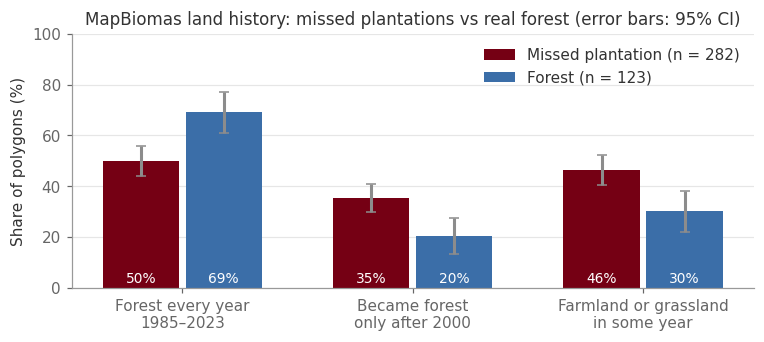

In [12]:
f4 = {c: report_binary(c, "4 Land history", mi, fo, "missed plantation", "forest")
      for c in ["forest_every_year", "after2000", "farm_any"]}
f4c = report_continuous("n_class_changes", "4 Land history")

fig, ax = plt.subplots(figsize=(8, 3))
names4 = {"forest_every_year": "Forest every year\n1985–2023", "after2000": "Became forest\nonly after 2000",
          "farm_any": "Farmland or grassland\nin some year"}
xpos = np.arange(3); w = 0.36
for j, (grpname, colr, key_pct, key_n, key_N) in enumerate([("Missed plantation (n = 282)", PAL["plantation"], "pct_a", "n_a", "N_a"),
                                                          ("Forest (n = 123)", PAL["forest"], "pct_b", "n_b", "N_b")]):
    vals = [f4[c][key_pct] for c in names4]
    # normal-approximation 95% CI for each share
    errs = [1.96 * 100 * np.sqrt((f4[c][key_pct] / 100) * (1 - f4[c][key_pct] / 100) / f4[c][key_N]) for c in names4]
    ax.bar(xpos + (j - 0.5) * w, vals, w * 0.92, color=colr, label=grpname, yerr=errs, capsize=3, ecolor=PAL["grey"])
    for xi, v in zip(xpos + (j - 0.5) * w, vals):
        ax.text(xi, 2, f"{v:.0f}%", ha="center", color="white", fontsize=9)
ax.set_xticks(xpos, list(names4.values())); ax.set_ylabel("Share of polygons (%)"); ax.set_ylim(0, 100)
ax.set_title("MapBiomas land history: missed plantations vs real forest (error bars: 95% CI)")
ax.legend(loc="upper right"); ax.grid(axis="x", visible=False)
savefig(fig, "01d4_land_history"); plt.show()

**Result.** Compared with real forest, missed plantations are:
- **less often** forest in every year: 50% vs 69% (OR 0.45);
- **more often** forest only after 2000: 35% vs 20% (OR 2.15);
- **more often** farmland or grassland at some point: 46% vs 30% (OR 2.02).

They also change class more often (AUC 0.65). So MapBiomas' *own history* contains a signal
that its 2020 label ignores.

### Finding 5: patch size is not a signal

**Hypothesis.** Plantation harvests might be larger, block-shaped clearings.

**Measurement.** Polygon area in m² (geodesic).
**Limitation:** the polygons are Cropin's alert outlines, so their size reflects how alerts are
drawn, not necessarily the size of the stand.

area_m2: median plantation 275 vs forest 271 | AUC 0.504 (95% CI 0.446-0.565), higher in plantations | Mann-Whitney p = 9.0e-01


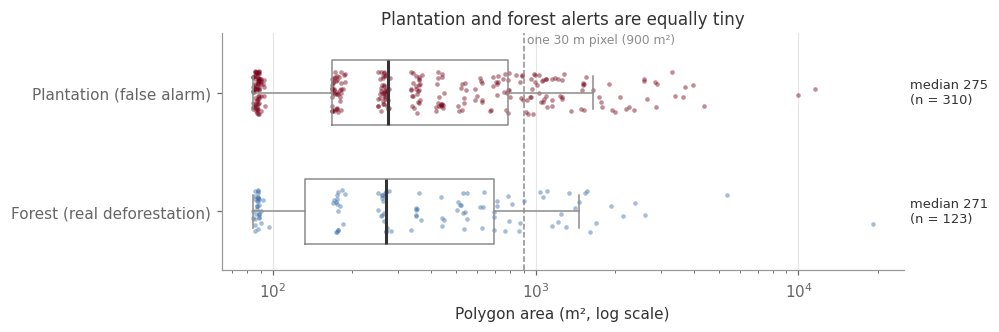

In [13]:
f5 = report_continuous("area_m2", "5 Patch area")
fig, ax = plt.subplots(figsize=(8, 2.8))
dist_plot(ax, d, "area_m2", "Polygon area (m², log scale)", log=True)
ax.axvline(900, color=PAL["grey"], ls="--", lw=1); ax.text(930, 1.42, "one 30 m pixel (900 m²)", fontsize=8, color=PAL["grey"])
ax.set_title("Plantation and forest alerts are equally tiny")
savefig(fig, "01d5_area"); plt.show()

**Result.** Median area is 275 m² for plantations and 271 m² for forests: AUC 0.50, p = 0.90.
There is no difference.

**For Deepak, who asked what "equally tiny" means.** This statement is about the QC cases only:
within Cropin's alerts, a plantation alert and a forest alert have the same size distribution. It
says nothing about stand sizes in the landscape. The practical message is that any model must
work from 10 m inputs, because most alerts are smaller than one 30 m pixel.

### Finding 6: yearly NDVI does not separate the groups

**Hypothesis.** A plantation harvest is a sudden loss of greenness, so plantations should show
yearly NDVI dips (low 10th percentile), and native forest should not.

**Measurement.** Yearly Sentinel-2 NDVI per polygon, 2019–2024 (section b explains why not
2017–18 or 2025):
- `min_p10`: lowest yearly 10th percentile;
- `any_dip`: any year with p10 < 0.5;
- `mean_med`: average yearly median.

**Limitations:**
- **Harvest timing.** Rotations are 6–8 years for eucalyptus and 15+ years for pine, so the last
  harvest before the 2026 one may predate 2019.
- **Seasonality lost.** Yearly summaries discard seasonal shape, which is where Cropin's SAG
  signal lives (notebook 02).
- **Clouds.** Cloud and shadow residue can create false dips.

min_p10: median plantation 0.604 vs forest 0.611 | AUC 0.507 (95% CI 0.447-0.567), lower in plantations | Mann-Whitney p = 8.2e-01
any_dip: plantation 28.7% (89/310) vs forest 25.2% (31/123) | OR 1.20 | Fisher p = 4.8e-01


mean_med: median plantation 0.861 vs forest 0.853 | AUC 0.596 (95% CI 0.535-0.657), higher in plantations | Mann-Whitney p = 1.8e-03


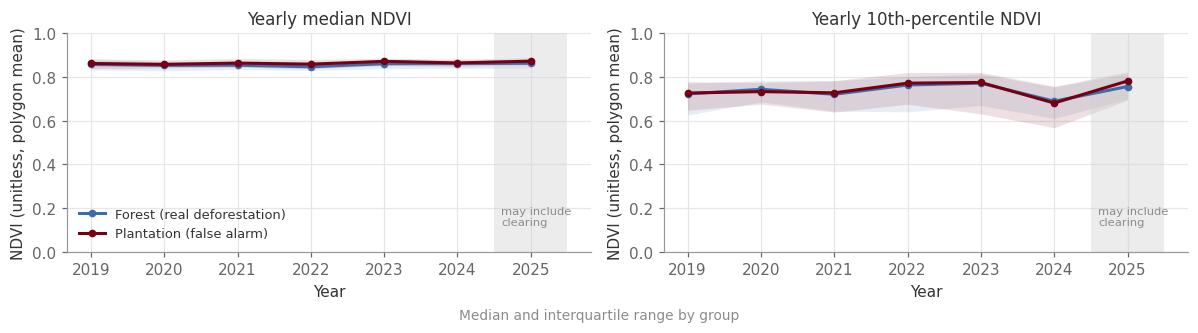

In [14]:
f6a = report_continuous("min_p10", "6 NDVI")
f6b = report_binary("any_dip", "6 NDVI", pl, fo, "plantation", "forest")
f6c = report_continuous("mean_med", "6 NDVI")

yrs6 = range(2019, 2026)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
for ax, prefix, ttl in [(axs[0], "ndvi_med", "Yearly median NDVI"), (axs[1], "ndvi_p10", "Yearly 10th-percentile NDVI")]:
    for lab in ["forest", "plantation"]:
        sub = d.loc[d.qc_label == lab, [f"{prefix}_{y}" for y in yrs6]]
        med, q1, q3 = sub.median(), sub.quantile(.25), sub.quantile(.75)
        ax.plot(list(yrs6), med.values, color=PAL[lab], marker="o", ms=4, label=LABELS[lab])
        ax.fill_between(list(yrs6), q1.values, q3.values, color=PAL[lab], alpha=0.12, linewidth=0)
    ax.axvspan(2024.5, 2025.5, color=PAL["light"], alpha=0.4, lw=0); ax.text(2024.6, 0.12, "may include\nclearing", fontsize=7.5, color=PAL["grey"])
    ax.set_title(ttl); ax.set_xlabel("Year"); ax.set_ylabel("NDVI (unitless, polygon mean)"); ax.set_ylim(0, 1)
axs[0].legend(loc="lower left", fontsize=8.5)
fig.suptitle("Median and interquartile range by group", fontsize=9, color=PAL["grey"], y=0.02)
plt.tight_layout(); savefig(fig, "01d6_ndvi"); plt.show()

**Result.**
- **Dips.** The lowest yearly p10 does not differ (AUC ≈ 0.51). The share with a dip below 0.5
  is similar for plantations and forests (Fisher p ≈ 0.5).
- **Overall greenness.** Plantations are a touch greener on average over 2019–24 (`mean_med`,
  AUC ≈ 0.60). The medians differ only by about 0.01 NDVI, a trivial gap for a classifier. With
  the original 2017–24 window this was not significant (section f).
- **Verdict.** Yearly NDVI does not help much. Seasonality (notebook 02) and longer Landsat
  histories (CCDC) are the logical next steps for the time-series idea.

### All tests together, with the Holm correction
Holm-adjusted p-values are the ones to quote. The family is every hypothesis test in section d.
The threshold tables are descriptive and not part of it.

In [15]:
tests = pd.DataFrame(TESTS)
tests["p_holm"] = holm(tests["p_raw"])
tests["significant_after_holm (5%)"] = tests["p_holm"] < 0.05
show = tests.copy(); show["p_raw"] = show["p_raw"].map("{:.1e}".format); show["p_holm"] = show["p_holm"].map("{:.1e}".format)
display(show)

,finding,feature,test,comparison,effect,p_raw,p_holm,significant_after_holm (5%)
0,1 Natural Forests,nf_prob,Mann-Whitney U,plantation vs forest,AUC 0.72 (0.66-0.77),1.3e-12,1.4e-11,True
1,2 Height,height_mean,Mann-Whitney U,plantation vs forest,AUC 0.71 (0.65-0.76),2.3e-11,2.3e-10,True
2,3 Height SD (30 m circle),height_sd_30m,Mann-Whitney U,plantation vs forest,AUC 0.66 (0.61-0.72),1.2e-07,1.1e-06,True
3,4 Land history,forest_every_year,Fisher exact,missed plantation vs forest,OR 0.45,4.7e-04,3.3e-03,True
4,4 Land history,after2000,Fisher exact,missed plantation vs forest,OR 2.15,2.3e-03,1.1e-02,True
5,4 Land history,farm_any,Fisher exact,missed plantation vs forest,OR 2.02,2.2e-03,1.1e-02,True
6,4 Land history,n_class_changes,Mann-Whitney U,plantation vs forest,AUC 0.65 (0.60-0.69),1.8e-07,1.5e-06,True
7,5 Patch area,area_m2,Mann-Whitney U,plantation vs forest,AUC 0.50 (0.45-0.57),9.0e-01,1.0e+00,False
8,6 NDVI,min_p10,Mann-Whitney U,plantation vs forest,AUC 0.51 (0.45-0.57),8.2e-01,1.0e+00,False
9,6 NDVI,any_dip,Fisher exact,plantation vs forest,OR 1.20,4.8e-01,1.0e+00,False


**Reading it.** After the correction, the following remain clearly significant:
- Natural Forests probability, height and height SD;
- all four land-history measures.

Patch area and the NDVI dip measures do not. The small `mean_med` difference survives the
correction, but its effect is tiny. Remember these p-values only measure surprise *within this
biased, post-hoc sample*. The honest status of every finding is "promising hypothesis".

## e. Finding 7: combining signals in one model

**Model.** A **logistic regression** turns several features into one probability of
"plantation". We use it because it is the simplest model that can combine features, and its
coefficients are directly interpretable. Features are **standardized** (mean 0, SD 1) before
fitting, so their coefficients can be compared, and the default mild L2 regularisation applies
equally to all of them.

**Features** (as in the preliminary analysis):
- `nf_prob`, `height_mean` and `height_sd_30m`;
- `n_class_changes` and `n_yrs_forest`.

**Honest evaluation.** A model scored on the data it was fitted on looks better than it is.
**Cross-validation (CV)** fits on 80% of the polygons and scores on the held-out 20%, five times,
so every polygon is predicted by a model that never saw it.

In [16]:
F7 = ["nf_prob", "height_mean", "height_sd_30m", "n_class_changes", "n_yrs_forest"]
COMBOS = {"Natural Forests only": ["nf_prob"], "Height only": ["height_mean"],
          "Class changes only": ["n_class_changes"], "NF + height": ["nf_prob", "height_mean"],
          "All five features": F7}
X, y = d[F7].values, d["y"].values
SEEDS = range(20)

### (i) The original evaluation: stratified 5-fold CV, repeated over 20 seeds
"Stratified" means each fold keeps the 72/28 plantation/forest mix. Repeating with 20 different
random splits shows how much the AUC depends on the luck of the split.

In [17]:
res_strat = {}
for name, cols in COMBOS.items():
    r, _ = cv_evaluate(d[cols].values, y, None, "stratified", SEEDS)
    res_strat[name] = r
display(pd.DataFrame({k: dict(cv_auc_mean=v.auc.mean(), cv_auc_sd=v.auc.std()) for k, v in res_strat.items()}).T.round(3))

,cv_auc_mean,cv_auc_sd
Natural Forests only,0.711,0.003
Height only,0.702,0.002
Class changes only,0.634,0.007
NF + height,0.799,0.003
All five features,0.825,0.004


### (ii) Spatially blocked CV
The polygons cluster: a third are within 2 km of another one. Neighbouring polygons share soil,
climate, farm management and even image artefacts. With random folds, a test polygon usually has
a near-twin in the training set, so the score partly measures *memory of a place* rather than
transferable knowledge.

**Spatial blocking** keeps whole areas together. We group the polygons into **20 clusters of
nearby centroids** (KMeans on lat/lon, seed 0) and use `StratifiedGroupKFold`, so a whole
cluster is always in either training or test. As a sensitivity check we repeat this with a
**0.25° grid** (about 25 km cells; 111 occupied cells).

In [18]:
g_km = spatial_groups(d, k=20, seed=SEED)
g_grid = grid_groups(d, 0.25)
sizes = pd.Series(g_km).value_counts()
print(f"KMeans blocks: {len(sizes)} clusters, sizes {sizes.min()}–{sizes.max()} (median {int(sizes.median())})")
print(f"0.25° grid: {len(set(g_grid))} occupied cells")

schemes = {"Random (stratified)": ("stratified", None), "Spatial: 20 KMeans blocks": ("group", g_km),
           "Spatial: 0.25° grid": ("group", g_grid)}
res_all = {}
for sname, (kind, grp) in schemes.items():
    for name in ["Natural Forests only", "Height only", "NF + height", "All five features"]:
        r, oof = cv_evaluate(d[COMBOS[name]].values, y, grp, kind, SEEDS)
        res_all[(sname, name)] = (r, oof)
auc_tab = pd.DataFrame({s: {n: f"{res_all[(s, n)][0].auc.mean():.3f} ± {res_all[(s, n)][0].auc.std():.3f}"
                            for n in ["Natural Forests only", "Height only", "NF + height", "All five features"]} for s in schemes})
display(auc_tab)

# AUC uncertainty from the sample itself (bootstrap of seed-0 pooled out-of-fold predictions)
for s in schemes:
    p0 = res_all[(s, "All five features")][1][0]
    a, lo, hi = auc_ci(y, p0, N_BOOT, SEED)
    print(f"{s:28s} all five features, seed 0: AUC {a:.3f} (bootstrap 95% CI {lo:.3f}-{hi:.3f})")

KMeans blocks: 20 clusters, sizes 1–79 (median 17)
0.25° grid: 111 occupied cells


,Random (stratified),Spatial: 20 KMeans blocks,Spatial: 0.25° grid
Natural Forests only,0.711 ± 0.003,0.700 ± 0.006,0.702 ± 0.007
Height only,0.702 ± 0.002,0.671 ± 0.009,0.692 ± 0.007
NF + height,0.799 ± 0.003,0.782 ± 0.006,0.794 ± 0.005
All five features,0.825 ± 0.004,0.811 ± 0.005,0.821 ± 0.005


Random (stratified)          all five features, seed 0: AUC 0.829 (bootstrap 95% CI 0.785-0.871)


Spatial: 20 KMeans blocks    all five features, seed 0: AUC 0.808 (bootstrap 95% CI 0.762-0.852)


Spatial: 0.25° grid          all five features, seed 0: AUC 0.819 (bootstrap 95% CI 0.776-0.862)


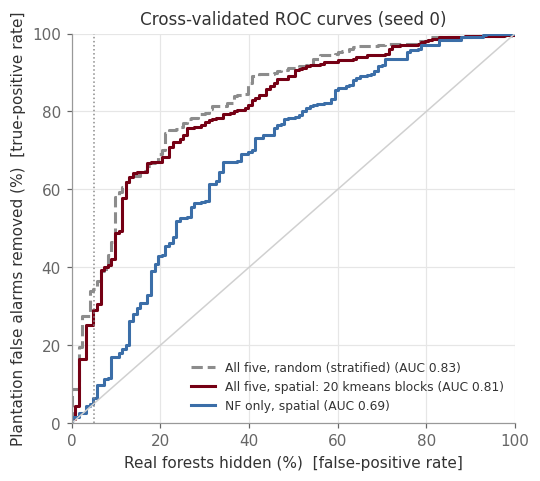

In [19]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
styles = {"Random (stratified)": (PAL["grey"], "--"), "Spatial: 20 KMeans blocks": (PAL["plantation"], "-")}
for s, (c, ls) in styles.items():
    p0 = res_all[(s, "All five features")][1][0]
    fpr, tpr, _ = roc_curve(y, p0)
    ax.plot(100 * fpr, 100 * tpr, color=c, ls=ls, label=f"All five, {s.lower()} (AUC {roc_auc_score(y, p0):.2f})")
p_nf = res_all[("Spatial: 20 KMeans blocks", "Natural Forests only")][1][0]
fpr, tpr, _ = roc_curve(y, p_nf); ax.plot(100 * fpr, 100 * tpr, color=PAL["forest"], label=f"NF only, spatial (AUC {roc_auc_score(y, p_nf):.2f})")
ax.plot([0, 100], [0, 100], color=PAL["light"], lw=1)
ax.axvline(5, color=PAL["grey"], ls=":", lw=1)
ax.set_xlabel("Real forests hidden (%)  [false-positive rate]"); ax.set_ylabel("Plantation false alarms removed (%)  [true-positive rate]")
ax.set_title("Cross-validated ROC curves (seed 0)"); ax.legend(fontsize=8, loc="lower right")
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
savefig(fig, "01e_roc"); plt.show()

**Reading it.**
- **Random CV.** The five-feature model reaches a CV AUC of about **0.82**, reproducing the original 0.824.
- **Spatial CV.** Under spatial blocking it drops slightly, to about **0.81** (KMeans blocks) or
  0.82 (grid). The leakage from neighbouring polygons is real but small, so the signal mostly
  transfers to unseen areas *within the region these QC cases cover*.
- **Seed vs sample uncertainty.** The ± across seeds is tiny (±0.005). The bootstrap CI, which
  reflects the small sample itself, is much wider (about ±0.04). The CI is the uncertainty to quote.

### (iii) The operating point: share of plantations removed while hiding ≤ 5% of real forest
Cropin's priority is not to hide real deforestation. A natural rule is therefore: *flag an
alert as "plantation" only when the model is confident enough that at most 5% of real forests
would be flagged*.

**Two ways to pick that cut-off.**
- **Optimistic (original method).** Pick the cut-off by looking at the CV predictions of *all*
  polygons, then score the same predictions. The cut-off has seen the test answers.
- **Nested (honest).** Inside each training fold, run a second, inner CV on the training data
  only, and pick the cut-off where at most 5% of *training* forests are flagged. Then apply it,
  unchanged, to the untouched test fold. This mimics using the rule on new alerts.

With only 123 forests, "5%" is just 6 polygons, so a single forest more or less moves the result
by about 1 point. We therefore report the mean and spread over 20 seeds.

In [20]:
rows = []
for s in schemes:
    for name in ["Natural Forests only", "Height only", "NF + height", "All five features"]:
        r = res_all[(s, name)][0]
        rows.append({"CV scheme": s, "features": name,
                     "optimistic: removed %": f"{r.opt_caught.mean():.1f} ± {r.opt_caught.std():.1f}",
                     "optimistic: forest hidden %": f"{r.opt_hidden.mean():.1f}",
                     "nested: removed %": f"{r.nest_caught.mean():.1f} ± {r.nest_caught.std():.1f}",
                     "nested: forest hidden %": f"{r.nest_hidden.mean():.1f} ± {r.nest_hidden.std():.1f}"})
op_tab = pd.DataFrame(rows).set_index(["CV scheme", "features"])
display(op_tab)
mb_caught = 100 * (pl.mb_2020 == 9).mean(); mb_hidden = 100 * (fo.mb_2020 == 9).mean()
print(f"MapBiomas C9 2020 as a filter ('class 9 = plantation'): removes {mb_caught:.1f}% of plantations, hides {mb_hidden:.1f}% of forest")

optimistic: removed % optimistic: forest hidden % nested: removed % nested: forest hidden %
CV scheme                 features                                                                                                        
Random (stratified)       Natural Forests only            15.7 ± 3.5                         4.9        12.9 ± 2.0               4.4 ± 0.8
                          Height only                     19.3 ± 2.5                         4.9        14.3 ± 1.6               4.7 ± 0.7
                          NF + height                     17.1 ± 1.9                         4.9        15.5 ± 1.1               4.2 ± 0.9
                          All five features               30.6 ± 2.6                         4.9        29.5 ± 1.9               4.7 ± 1.1
Spatial: 20 KMeans blocks Natural Forests only            10.0 ± 4.2                         4.8        11.8 ± 2.6               4.5 ± 1.1
                          Height only                     16.1 ± 1.6                         4.9        13.2 ± 2.6               5.2 ± 1.3
                          NF + height                     16.7 ± 1.6                         4.8        15.7 ± 1.0               4.7 ± 0.9
                          All five features               28.7 ± 2.2                         4.5        30.0 ± 2.4               5.3 ± 1.1
Spatial: 0.25° grid       Natural Forests only            14.2 ± 4.3                         4.9        15.4 ± 2.6               5.1 ± 0.9
                          Height only                     18.5 ± 2.5                         4.9        14.6 ± 1.4               4.9 ± 0.4
                          NF + height                     17.4 ± 1.7                         4.9        16.7 ± 1.5               5.6 ± 1.3
                          All five features               31.3 ± 3.5                         4.5        30.8 ± 1.9               5.0 ± 1.1

MapBiomas C9 2020 as a filter ('class 9 = plantation'): removes 3.5% of plantations, hides 0.0% of forest


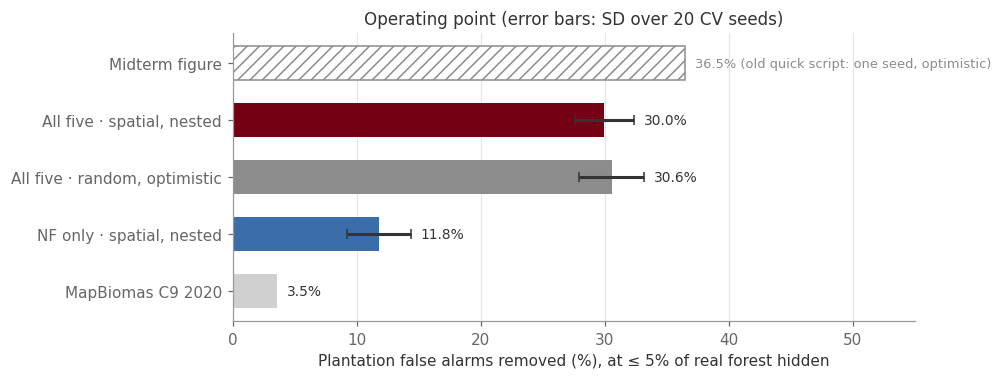

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.4))
bars = [("MapBiomas C9 2020", mb_caught, 0, PAL["light"]),
        ("NF only · spatial, nested", res_all[("Spatial: 20 KMeans blocks", "Natural Forests only")][0].nest_caught.mean(),
         res_all[("Spatial: 20 KMeans blocks", "Natural Forests only")][0].nest_caught.std(), PAL["forest"]),
        ("All five · random, optimistic", res_all[("Random (stratified)", "All five features")][0].opt_caught.mean(),
         res_all[("Random (stratified)", "All five features")][0].opt_caught.std(), PAL["grey"]),
        ("All five · spatial, nested", res_all[("Spatial: 20 KMeans blocks", "All five features")][0].nest_caught.mean(),
         res_all[("Spatial: 20 KMeans blocks", "All five features")][0].nest_caught.std(), PAL["plantation"])]
for i, (lab, v, sd, c) in enumerate(bars):
    ax.barh(i, v, color=c, height=0.6, xerr=sd if sd else None, ecolor=PAL["ink"], capsize=3)
    ax.text(v + sd + 0.8, i, f"{v:.1f}%", va="center", fontsize=9)
ax.barh(len(bars), 36.5, color="white", edgecolor=PAL["grey"], hatch="///", height=0.6)
ax.text(37.3, len(bars), "36.5% (old quick script: one seed, optimistic)", va="center", fontsize=8.5, color=PAL["grey"])
ax.set_yticks(range(len(bars) + 1), [b[0] for b in bars] + ["Midterm figure"])
ax.set_xlabel("Plantation false alarms removed (%), at ≤ 5% of real forest hidden")
ax.set_title("Operating point (error bars: SD over 20 CV seeds)"); ax.set_xlim(0, 55)
ax.grid(axis="y", visible=False)
savefig(fig, "01e_operating_point"); plt.show()

**Reading it.**
- **Headline.** At ≤ 5% of real forest hidden, the five-feature model removes about **30% of
  plantation false alarms** under honest (nested, spatially blocked) evaluation. MapBiomas removes
  3.5%. Natural Forests alone removes about half as many as the model.
- **Why not 36.5%?** The midterm figure came from a **single random split (seed 0)**, the
  3rd-luckiest of 20 for that recipe, and from unstandardized features. Section f shows this
  exactly.
- **Nested vs optimistic.** These differ by only about a point here. The bigger lesson is that
  any one split can be off by ±3 points.
- **Height alone transfers worst.** Its AUC falls from 0.70 to 0.67 under KMeans blocking,
  consistent with plantation height varying by region (species, age, site).
- **The 5% target can slip.** Under nested spatial CV the forest actually hidden is about 5.3%
  on average (±1.1). A cut-off chosen in one area does not transfer exactly to another. A real
  deployment would need a safety margin and checks on fresh alerts.

### (iv) Per-class precision and recall (Deepak's request)
For the nested, spatially blocked rule (pooled over the 20 seeds):
- **plantation recall**: share of plantations flagged;
- **plantation precision**: of everything flagged, the share that really is plantation;
- **forest recall**: share of real forest kept as an alert;
- **forest precision**: of the alerts kept, the share that is real forest.

We also show a plain 0.5 probability cut-off, and MapBiomas.

⚠️ **Precision depends on the class mix.** This sample is 72% plantations; Cropin's real alert
stream is unknown. With fewer plantations among real alerts, plantation precision would be lower.
Recall does not depend on the mix.

In [22]:
r_sp = res_all[("Spatial: 20 KMeans blocks", "All five features")][0]
pc_nested = per_class_metrics(r_sp.TP.sum(), r_sp.FP.sum(), r_sp.FN.sum(), r_sp.TN.sum())
pc_nested["n_true"] = (pc_nested["n_true"] / len(SEEDS)).astype(int)
p0 = res_all[("Spatial: 20 KMeans blocks", "All five features")][1][0]
f05 = p0 >= 0.5
pc_05 = per_class_metrics(int((f05 & (y == 1)).sum()), int((f05 & (y == 0)).sum()), int((~f05 & (y == 1)).sum()), int((~f05 & (y == 0)).sum()))
fmb = (d.mb_2020 == 9).values
pc_mb = per_class_metrics(int((fmb & (y == 1)).sum()), int((fmb & (y == 0)).sum()), int((~fmb & (y == 1)).sum()), int((~fmb & (y == 0)).sum()))
display(pd.concat({"Model, nested ≤5% rule (spatial CV)": pc_nested, "Model, p ≥ 0.5 (spatial CV, seed 0)": pc_05,
                   "MapBiomas C9 2020 class 9": pc_mb}).round(3))

precision  recall  n_true
Model, nested ≤5% rule (spatial CV) plantation (flagged)      0.934   0.300     310
                                    forest (kept)             0.349   0.947     123
Model, p ≥ 0.5 (spatial CV, seed 0) plantation (flagged)      0.821   0.887     310
                                    forest (kept)             0.643   0.512     123
MapBiomas C9 2020 class 9           plantation (flagged)      1.000   0.035     310
                                    forest (kept)             0.291   1.000     123

**Reading it.**
- **At the cautious cut-off.** About 9 in 10 flagged alerts really are plantations, and
  real-forest recall stays around 95%. But only about 3 in 10 plantations are flagged.
- **At p ≥ 0.5.** The model flags most plantations but hides a large share of real forest.
  That trade-off is unacceptable for EUDR.
- **The choice is Cropin's.** The cost of a missed deforestation event against a false alarm is
  a business decision. Cropin told us they have no number yet.

### (v) What drives the model: standardized coefficients with bootstrap CIs
Each coefficient is the change in the log-odds of "plantation" for a one-SD increase in the
feature, holding the others fixed. CIs come from refitting on 2,000 bootstrap resamples.
**Caution:** the features are correlated (e.g. `n_yrs_forest` and `n_class_changes`), so
individual coefficients can trade off against each other. Read signs and rough sizes, not exact values.

,coef,ci_low,ci_high
nf_prob,-0.77,-1.10,-0.52
height_mean,0.98,0.71,1.34
height_sd_30m,0.30,0.05,0.60
n_class_changes,0.93,0.44,1.49
n_yrs_forest,0.24,-0.12,0.59


feature correlations:


,nf_prob,height_mean,height_sd_30m,n_class_changes,n_yrs_forest
nf_prob,1.00,-0.04,-0.25,-0.19,0.18
height_mean,-0.04,1.00,0.11,-0.04,0.00
height_sd_30m,-0.25,0.11,1.00,0.17,-0.09
n_class_changes,-0.19,-0.04,0.17,1.00,-0.64
n_yrs_forest,0.18,0.00,-0.09,-0.64,1.00


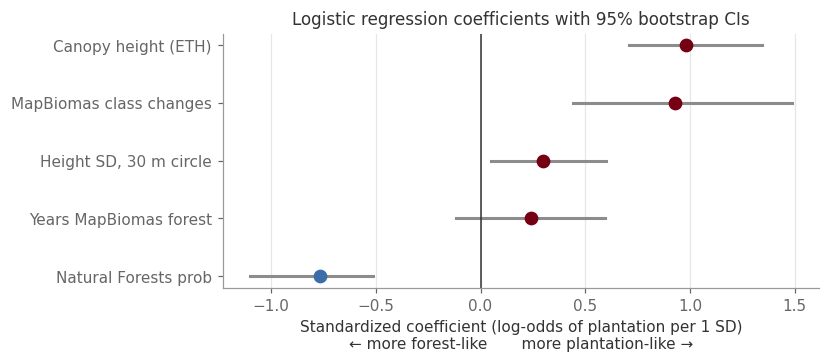

In [23]:
coefs = bootstrap_coefs(X, y, F7, N_BOOT, SEED)
display(coefs.round(2))
print("feature correlations:"); display(d[F7].corr().round(2))
fig, ax = plt.subplots(figsize=(7, 3))
order_c = coefs.sort_values("coef").index
nice = {"nf_prob": "Natural Forests prob", "height_mean": "Canopy height (ETH)", "height_sd_30m": "Height SD, 30 m circle",
        "n_class_changes": "MapBiomas class changes", "n_yrs_forest": "Years MapBiomas forest"}
for i, f in enumerate(order_c):
    c = coefs.loc[f]; colr = PAL["plantation"] if c.coef > 0 else PAL["forest"]
    ax.plot([c.ci_low, c.ci_high], [i, i], color=PAL["grey"], lw=2); ax.plot(c.coef, i, "o", color=colr, ms=8)
ax.axvline(0, color=PAL["ink"], lw=1)
ax.set_yticks(range(len(order_c)), [nice[f] for f in order_c])
ax.set_xlabel("Standardized coefficient (log-odds of plantation per 1 SD)\n← more forest-like       more plantation-like →")
ax.set_title("Logistic regression coefficients with 95% bootstrap CIs"); ax.grid(axis="y", visible=False)
savefig(fig, "01e_coefficients"); plt.show()

**Reading it.**
- **Pushes towards plantation:** greater height and more MapBiomas class changes.
- **Pushes towards forest:** higher Natural Forests probability.
- **Weak:** height SD is small and only just clear of zero (CI 0.05–0.60). The CI for
  years-as-forest crosses zero. That is unsurprising, because it is strongly correlated (r = −0.64)
  with class changes, which carries the land-history signal.
- **What this means.** Three independent kinds of information each add something: a
  "naturalness" map, structure (height) and land history.

## f. Reproducibility check against the preliminary analysis
We compare against `docs/old_analysis/stats.json` and `c7.json`, copied unchanged from
`_handoff/reference/old_analysis/`. They contain aggregate statistics only. We do not force a
match: where numbers differ, the table says why.

In [24]:
old = json.load(open(ROOT / "docs/old_analysis/stats.json"))
old_c7 = json.load(open(ROOT / "docs/old_analysis/c7.json"))
def new_auc(col): a, lo, hi = auc_ci(y, d[col], N_BOOT, SEED); return f"{a:.3f} [{lo:.3f}, {hi:.3f}]"
def old_auc(k): a = old[k]["auc"]; return f"{a[0]:.3f} [{a[1]:.3f}, {a[2]:.3f}]"

# exact replication of the old operating point: raw (unstandardized) LR, one split with seed 0
p_old = cross_val_predict(LogisticRegression(max_iter=1000), d[F7], y,
                          cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
t_old = threshold_hiding_at_most(p_old[y == 0]); old_rep = 100 * (p_old[y == 1] >= t_old).mean()
raw_seeds = []
for s in SEEDS:
    pp = cross_val_predict(LogisticRegression(max_iter=1000), d[F7], y, cv=StratifiedKFold(5, shuffle=True, random_state=s), method="predict_proba")[:, 1]
    raw_seeds.append(100 * (pp[y == 1] >= threshold_hiding_at_most(pp[y == 0])).mean())
raw_seeds = np.array(raw_seeds)

r_strat5 = res_all[("Random (stratified)", "All five features")][0]
rows = [
    ("AUC Natural Forests", old_auc("nf_prob"), new_auc("nf_prob"), "same data and method"),
    ("AUC height", old_auc("height_mean"), new_auc("height_mean"), "same point AUC; CI ends differ in 3rd decimal (*)"),
    ("AUC height SD 30 m", old_auc("height_sd_30m"), new_auc("height_sd_30m"), "same point AUC (*)"),
    ("AUC area", old_auc("area_m2"), new_auc("area_m2"), "same point AUC (*)"),
    ("AUC class changes", old_auc("n_class_changes"), new_auc("n_class_changes"), "same point AUC (*)"),
    ("AUC min NDVI p10 2017–24", old_auc("min_p10_17_24"), new_auc("min_p10_17_24"), "same definition reproduced"),
    ("AUC mean NDVI median", old_auc("mean_med"), f"{new_auc('mean_med_17_24')} (2017–24) / {new_auc('mean_med')} (2019–24)", "new default window 2019–24 (section b)"),
    ("forest every year: missed vs forest", f"{old['forest_all']['missed_pct']}% vs {old['forest_all']['forest_pct']}%, OR {old['forest_all']['odds_ratio']}",
        f"{f4['forest_every_year']['pct_a']:.1f}% vs {f4['forest_every_year']['pct_b']:.1f}%, OR {f4['forest_every_year']['odds_ratio']:.2f}", "same"),
    ("after 2000", f"{old['after2000']['missed_pct']}% vs {old['after2000']['forest_pct']}%, OR {old['after2000']['odds_ratio']}",
        f"{f4['after2000']['pct_a']:.1f}% vs {f4['after2000']['pct_b']:.1f}%, OR {f4['after2000']['odds_ratio']:.2f}", "same"),
    ("farmland ever", f"{old['farm_any']['missed_pct']}% vs {old['farm_any']['forest_pct']}%, OR {old['farm_any']['odds_ratio']}",
        f"{f4['farm_any']['pct_a']:.1f}% vs {f4['farm_any']['pct_b']:.1f}%, OR {f4['farm_any']['odds_ratio']:.2f}", "same"),
    ("any NDVI dip (plant vs forest)", f"{old['dip']['plant']}% vs {old['dip']['forest']}%, p {old['dip']['p']}",
        f"2017–24: {100*pl.any_dip_17_24.mean():.1f}% vs {100*fo.any_dip_17_24.mean():.1f}% / 2019–24: {f6b['pct_a']:.1f}% vs {f6b['pct_b']:.1f}%, p {f6b['p']:.2f}", "2019–24 is the new default"),
    ("CV AUC all five (20 seeds)", f"{old['combos']['NF + height + variability + history'][0]} ± {old['combos']['NF + height + variability + history'][1]}",
        f"{r_strat5.auc.mean():.3f} ± {r_strat5.auc.std():.3f}", "now standardized; essentially same"),
    ("CV AUC NF + height", f"{old['combos']['NF + height'][0]}", f"{res_all[('Random (stratified)', 'NF + height')][0].auc.mean():.3f}", "same"),
    ("Removed at ≤5% forest hidden, all five", f"{old['combo_at_5pct_forest_lost'][1]}%",
        f"exact old recipe: {old_rep:.1f}% | old recipe, 20 seeds: {raw_seeds.mean():.1f} ± {raw_seeds.std():.1f}% | "
        f"standardized, optimistic: {r_strat5.opt_caught.mean():.1f}% | spatial + nested: {r_sp.nest_caught.mean():.1f}%",
        "old number = one lucky seed (and unstandardized), with optimistic threshold"),
    ("Removed at ≤5%, NF only", f"{old_c7['Natural Forests alone']}%", f"{res_all[('Random (stratified)', 'Natural Forests only')][0].opt_caught.mean():.1f}% (optimistic, 20 seeds) / "
        f"{res_all[('Spatial: 20 KMeans blocks', 'Natural Forests only')][0].nest_caught.mean():.1f}% (spatial nested)", ""),
    ("Std. coefficients", ", ".join(f"{k} {v:+.2f}" for k, v in old["coef_std"].items()),
        ", ".join(f"{k} {v:+.2f}" for k, v in coefs.coef.items()), "same (full-data fit)"),
]
repro = pd.DataFrame(rows, columns=["quantity", "old (quick scripts)", "new (this notebook)", "note"])
with pd.option_context("display.max_colwidth", 140):
    display(repro)
print(f"Old recipe across 20 seeds: min {raw_seeds.min():.1f}%, max {raw_seeds.max():.1f}%; seed 0 = {raw_seeds[0]:.1f}% "
      f"(rank {int((raw_seeds > raw_seeds[0]).sum()) + 1} of 20)")
print("(*) the old script drew all bootstrap resamples from one random stream shared across features; "
      "here each feature restarts at seed 0, so CI endpoints differ slightly.")

,quantity,old (quick scripts),new (this notebook),note
0,AUC Natural Forests,"0.718 [0.661, 0.773]","0.718 [0.661, 0.773]",same data and method
1,AUC height,"0.706 [0.649, 0.761]","0.706 [0.649, 0.760]",same point AUC; CI ends differ in 3rd decimal (*)
2,AUC height SD 30 m,"0.663 [0.607, 0.714]","0.663 [0.607, 0.718]",same point AUC (*)
3,AUC area,"0.504 [0.444, 0.562]","0.504 [0.446, 0.564]",same point AUC (*)
4,AUC class changes,"0.648 [0.600, 0.693]","0.648 [0.599, 0.693]",same point AUC (*)
5,AUC min NDVI p10 2017–24,"0.515 [0.456, 0.573]","0.515 [0.457, 0.572]",same definition reproduced
6,AUC mean NDVI median,"0.553 [0.491, 0.615]","0.553 [0.491, 0.608] (2017–24) / 0.596 [0.532, 0.651] (2019–24)",new default window 2019–24 (section b)
7,forest every year: missed vs forest,"50.0% vs 69.1%, OR 0.45","50.0% vs 69.1%, OR 0.45",same
8,after 2000,"35.5% vs 20.3%, OR 2.15","35.5% vs 20.3%, OR 2.15",same
9,farmland ever,"46.5% vs 30.1%, OR 2.02","46.5% vs 30.1%, OR 2.02",same


Old recipe across 20 seeds: min 26.5%, max 37.4%; seed 0 = 36.5% (rank 3 of 20)
(*) the old script drew all bootstrap resamples from one random stream shared across features; here each feature restarts at seed 0, so CI endpoints differ slightly.


### Sensitivity: the 420 unique polygons
The same key results without the 13 repeated rows (section b).

In [25]:
du = dedupe(d); yu = du["y"].values
print(f"unique polygons: {len(du)} ({int(yu.sum())} plantation, {int((1 - yu).sum())} forest)")
sens = []
for col in ["nf_prob", "height_mean", "height_sd_30m", "n_class_changes", "area_m2", "min_p10"]:
    a1, l1, h1 = auc_ci(y, d[col], N_BOOT, SEED); a2, l2, h2 = auc_ci(yu, du[col], N_BOOT, SEED)
    sens.append((f"AUC {col}", f"{a1:.3f} [{l1:.3f}, {h1:.3f}]", f"{a2:.3f} [{l2:.3f}, {h2:.3f}]"))
mi_u, fo_u = du[du.group == "plant_missed"], du[du.y == 0]
for c in ["forest_every_year", "after2000", "farm_any"]:
    r = fisher_test(mi_u[c], fo_u[c])
    sens.append((f"{c} (missed vs forest)", f"OR {f4[c]['odds_ratio']:.2f}, p {f4[c]['p']:.1e}", f"OR {r['odds_ratio']:.2f}, p {r['p']:.1e}"))
g_km_u = spatial_groups(du, k=20, seed=SEED)
for sname, kind, g2 in [("random CV", "stratified", None), ("spatial CV (KMeans 20)", "group", g_km_u)]:
    r1 = res_all[("Random (stratified)" if kind == "stratified" else "Spatial: 20 KMeans blocks", "All five features")][0]
    r2, _ = cv_evaluate(du[F7].values, yu, g2, kind, SEEDS)
    sens.append((f"All five: CV AUC, {sname}", f"{r1.auc.mean():.3f}", f"{r2.auc.mean():.3f}"))
    sens.append((f"All five: removed at ≤5%, nested, {sname}", f"{r1.nest_caught.mean():.1f}% (hidden {r1.nest_hidden.mean():.1f}%)",
                 f"{r2.nest_caught.mean():.1f}% (hidden {r2.nest_hidden.mean():.1f}%)"))
display(pd.DataFrame(sens, columns=["quantity", "all 433", "420 unique"]))

unique polygons: 420 (302 plantation, 118 forest)


,quantity,all 433,420 unique
0,AUC nf_prob,"0.718 [0.661, 0.773]","0.724 [0.667, 0.779]"
1,AUC height_mean,"0.706 [0.649, 0.760]","0.712 [0.658, 0.763]"
2,AUC height_sd_30m,"0.663 [0.607, 0.718]","0.667 [0.605, 0.724]"
3,AUC n_class_changes,"0.648 [0.599, 0.693]","0.650 [0.600, 0.700]"
4,AUC area_m2,"0.504 [0.446, 0.564]","0.506 [0.448, 0.569]"
5,AUC min_p10,"0.507 [0.448, 0.569]","0.508 [0.445, 0.566]"
6,forest_every_year (missed vs forest),"OR 0.45, p 4.7e-04","OR 0.42, p 2.4e-04"
7,after2000 (missed vs forest),"OR 2.15, p 2.3e-03","OR 2.23, p 2.6e-03"
8,farm_any (missed vs forest),"OR 2.02, p 2.2e-03","OR 2.13, p 1.2e-03"
9,"All five: CV AUC, random CV",0.825,0.829


**Reading it.** Removing the repeats changes the numbers only slightly, and no conclusion
changes. The repeats are worth reporting to Cropin, but they do not drive any finding.

**Summary of the check.**
- **What reproduces exactly:** every single-feature statistic (AUCs, CIs, medians, Fisher
  tests), the CV AUC of 0.824 and the standardized coefficients. The raw data and the feature
  definitions are therefore what we thought they were.
- **What does not hold:** **36.5%**, the "plantations removed at ≤ 5% forest hidden" figure from
  the midterm. It *can* be reproduced exactly with the old recipe, but it is the 3rd-best of 20
  random splits for that recipe (range 26.5–37.4%). Over 20 splits the old recipe averages about 33%. With
  standardized features and honest nested, spatially blocked evaluation it is about **30%**.
  **Use ≈ 30% going forward**, together with the AUC CI.
- **NDVI:** the new default window (2019–24) changes the NDVI numbers slightly. The conclusion,
  that yearly NDVI is not useful, does not change.

## g. Caveats and next steps

**Caveats.** Read every number above with these in mind.
1. **Biased sample.** Every case was already called forest by Cropin's layer and was then
   cleared. None of this estimates accuracy on the whole landscape or on all alerts. Precision
   depends on the unknown real class mix.
2. **Repeated polygons.** 13 of the 433 rows repeat another polygon exactly. Results barely
   change without them (section f), but ask Cropin why.
3. **Exploratory.** Features were chosen after looking at these 433 cases. Even with the Holm
   correction and spatial CV, the results are hypotheses. Confirmation needs **new alerts**
   (Cropin offered a week of fresh ones) and the **MapBiomas reference points** as an independent set.
4. **Small numbers.** "5% of forest" means 6 polygons. Operating-point numbers move by several
   points with tiny changes, so quote AUCs with CIs.
5. **Measurement mismatches.**
   - `height_sd_30m` measures a circle around the polygon, not its interior.
   - `mb_*` is a 30 m mode on sub-pixel polygons.
   - ETH height is from 2020 and the clearings from 2026, so stands may have been harvested or
     replanted in between.
6. **Land history is MapBiomas' own opinion.** It is useful *because* it is available
   everywhere, but its errors are correlated with the 2020 label we are trying to fix.
7. **"It's not a model."** On 433 points this is a proof of concept for which *kinds* of
   information help (naturalness, height, history). It is not a deployable classifier.

**Next steps.**
- **Notebook 02** (data now exported):
  - benchmark Cropin's own forest layer and the MapBiomas 10 m products;
  - validate SAG on these cases for the first time;
  - test height variability *inside* stands with Meta 1 m;
  - add SAG and Meta to this model.
- **Reconcile with Julia:** MapBiomas release (10 m C4, 2025), the 14 dropped cases, one shared feature table.
- **Ask Cropin** for the CCDC script.
- **Test on the 2,290 MapBiomas reference points:** train there, evaluate on QC.
- **Map a small region of interest** and inspect it visually, as Deepak asked.